# Quantum Approximate Optimization Algorithm (QAOA): Max-Cut on the Zachary karate-club graph

## Problem
Max-Cut asks for a partition of the vertices of a graph $G=(V,E)$ into two sets that maximises the number of edges crossing the partition. It is NP-hard. QAOA (Farhi, Goldstone & Gutmann, 2014) prepares a parameterised quantum state whose measurement favours high-cut bitstrings. Here it is applied to a real social network, the Zachary karate club, in two sizes: a 12-node induced subgraph that can be simulated exactly, and the full 34-node graph, which is too large for a statevector and is solved with classical heuristics only.

## Data
* **Graph:** Zachary's karate club (W. W. Zachary, *J. Anthropological Research* 33, 452-473, 1977): 34 members, 78 friendships. It is loaded from `networkx.karate_club_graph()`, which ships with networkx and needs no download.
* **Subgraph:** the subgraph induced by members 0 to 11 (12 nodes), relabelled to 0-11. It is connected.

## Method
Cost (cut size) and the QAOA state with $p$ layers:

$$
C(z) = \sum_{(u,v)\in E} \tfrac12\,(1 - z_u z_v), \qquad z\in\{\pm1\}^n,
$$

$$
|\gamma,\beta\rangle = \prod_{k=1}^{p} e^{-i\beta_k \sum_j X_j}\, e^{-i\gamma_k \hat C}\; |+\rangle^{\otimes n}, \qquad
F_p(\gamma,\beta) = \langle \gamma,\beta|\hat C|\gamma,\beta\rangle .
$$

The state is simulated exactly as a $2^{n}$-dimensional vector (NumPy). The phase layer is diagonal and the mixer is a product of $R_X(2\beta)$ gates. For $p=1$, the NumPy result is cross-checked against a Qiskit circuit (`QuantumCircuit`, `Statevector`). Angles are optimised with COBYLA (`scipy.optimize`), with random restarts and a grid search for $p=1$.

Reported metrics: approximation ratio $r = F_p / C_{\max}$ (with $C_{\max}$ the brute-force optimum), probability of sampling an optimal cut, and the best cut seen in 2048 measurement shots.

Classical baselines: uniform random cuts, a greedy vertex-by-vertex assignment with 1-flip local search, and a Goemans-Williamson-style algorithm (semidefinite relaxation solved by a Burer-Monteiro factorisation, followed by 2000 random-hyperplane roundings).

In [1]:
import itertools, time
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from scipy.optimize import minimize
import qiskit
from qiskit import QuantumCircuit
from qiskit.quantum_info import SparsePauliOp, Statevector

SEED = 7
rng = np.random.default_rng(SEED)
print("networkx", nx.__version__, "| qiskit", qiskit.__version__)

G_full = nx.karate_club_graph()                     # 34 nodes, 78 edges (Zachary 1977)
G12 = nx.convert_node_labels_to_integers(G_full.subgraph(range(12)).copy(), ordering="sorted")
print(f"Full karate club: {G_full.number_of_nodes()} nodes, {G_full.number_of_edges()} edges")
print(f"12-node subgraph (members 0-11): {G12.number_of_nodes()} nodes, {G12.number_of_edges()} edges, "
      f"connected = {nx.is_connected(G12)}")
print("12-node edges:", sorted(G12.edges()))

networkx 3.6.1 | qiskit 2.5.0
Full karate club: 34 nodes, 78 edges
12-node subgraph (members 0-11): 12 nodes, 22 edges, connected = True
12-node edges: [(0, 1), (0, 2), (0, 3), (0, 4), (0, 5), (0, 6), (0, 7), (0, 8), (0, 10), (0, 11), (1, 2), (1, 3), (1, 7), (2, 3), (2, 7), (2, 8), (2, 9), (3, 7), (4, 6), (4, 10), (5, 6), (5, 10)]


In [2]:
def cut_values_all(edges, n):
    """Cut value of every bitstring 0..2^n-1 (bit q of the index = vertex q)."""
    idx = np.arange(2 ** n)
    bits = [(idx >> q) & 1 for q in range(n)]
    cut = np.zeros(2 ** n, dtype=float)
    for u, v in edges:
        cut += bits[u] ^ bits[v]
    return cut

def cut_of(assign, edges):
    return sum(assign[u] != assign[v] for u, v in edges)

edges12 = [tuple(e) for e in G12.edges()]
n12 = G12.number_of_nodes()
cut12 = cut_values_all(edges12, n12)
C_MAX12 = cut12.max()
OPT_MASK12 = cut12 == C_MAX12
print(f"Exact optimum (brute force over 2^{n12} = {2**n12} assignments): C_max = {C_MAX12:.0f}")
print(f"Number of optimal bitstrings (incl. global flips): {OPT_MASK12.sum()}")

Exact optimum (brute force over 2^12 = 4096 assignments): C_max = 16
Number of optimal bitstrings (incl. global flips): 16


In [3]:
def hadamard_all(psi, n):
    """Apply H on every qubit (fast Walsh-Hadamard transform, qubit q = bit q of the index)."""
    psi = psi.copy()
    for q in range(n):
        v = psi.reshape(2 ** (n - 1 - q), 2, 2 ** q)
        a, b = v[:, 0, :], v[:, 1, :]
        v = np.stack([a + b, a - b], axis=1)
        psi = v.reshape(-1)
    return psi / np.sqrt(2 ** n)

_POPCOUNT_CACHE = {}
def rx_all(psi, beta, n):
    """Apply exp(-i beta sum_j X_j) = H^{(x)n} exp(-i beta sum_j Z_j) H^{(x)n} to a statevector."""
    if n not in _POPCOUNT_CACHE:
        idx = np.arange(2 ** n)
        pc = np.zeros(2 ** n, dtype=np.int64)
        for q in range(n):
            pc += (idx >> q) & 1
        _POPCOUNT_CACHE[n] = n - 2 * pc          # sum_j (1 - 2 z_j) for each basis state
    phase = np.exp(-1j * beta * _POPCOUNT_CACHE[n])
    return hadamard_all(phase * hadamard_all(psi, n), n)

def qaoa_state(gammas, betas, cut_diag, n):
    psi = np.full(2 ** n, 1 / np.sqrt(2 ** n), dtype=complex)
    for g, b in zip(gammas, betas):
        psi = psi * np.exp(-1j * g * cut_diag)     # e^{-i gamma C}, diagonal
        psi = rx_all(psi, b, n)
    return psi

def qaoa_expectation(x, p, cut_diag, n):
    psi = qaoa_state(x[:p], x[p:], cut_diag, n)
    return float(np.real(np.vdot(psi, cut_diag * psi)))

# Cross-check the NumPy simulator against Qiskit for p = 1 at a random point
def qiskit_qaoa_expectation(gammas, betas, edges, n):
    qc = QuantumCircuit(n)
    qc.h(range(n))
    for g, b in zip(gammas, betas):
        for u, v in edges:
            qc.rzz(-g, u, v)                       # exp(-i g (1 - ZZ)/2) = global phase * RZZ(-g)
        for q in range(n):
            qc.rx(2 * b, q)
    op = SparsePauliOp.from_list([("I" * n, 0.5 * len(edges))] +
                                 [("".join("Z" if q in (u, v) else "I" for q in reversed(range(n))), -0.5)
                                  for u, v in edges])
    return float(Statevector(qc).expectation_value(op).real)

x_test = np.array([0.7, 0.4])
e_np = qaoa_expectation(x_test, 1, cut12, n12)
e_qk = qiskit_qaoa_expectation([x_test[0]], [x_test[1]], edges12, n12)
print(f"p=1 check at gamma=0.7, beta=0.4: NumPy <C> = {e_np:.10f}, Qiskit <C> = {e_qk:.10f}, "
      f"difference = {abs(e_np - e_qk):.2e}")

p=1 check at gamma=0.7, beta=0.4: NumPy <C> = 12.8728955670, Qiskit <C> = 12.8728955670, difference = 3.91e-14


In [4]:
def optimise_qaoa(p, cut_diag, n, n_starts=30, maxiter=400):
    best = None
    evals = 0
    for s in range(n_starts):
        x0 = rng.uniform(0, np.pi, 2 * p)
        x0[p:] = rng.uniform(0, np.pi / 2, p)
        res = minimize(lambda x: -qaoa_expectation(x, p, cut_diag, n), x0, method="COBYLA",
                       options={"maxiter": maxiter, "rhobeg": 0.4, "tol": 1e-9})
        evals += res.nfev
        if best is None or res.fun < best.fun:
            best = res
    return best, evals

def sample_best(x, p, cut_diag, n, shots=2048):
    psi = qaoa_state(x[:p], x[p:], cut_diag, n)
    probs = np.abs(psi) ** 2
    probs = probs / probs.sum()
    samples = rng.choice(2 ** n, size=shots, p=probs)
    return cut_diag[samples].max(), probs

RESULTS12 = {}
for p in [1, 2, 3]:
    t0 = time.time()
    res, nev = optimise_qaoa(p, cut12, n12)
    x = res.x
    exp_c = -res.fun
    best_shot, probs = sample_best(x, p, cut12, n12)
    p_opt = probs[OPT_MASK12].sum()
    RESULTS12[p] = dict(expectation=exp_c, ratio=exp_c / C_MAX12, p_opt=p_opt,
                        best_shot=best_shot, x=x, evals=nev, time=time.time() - t0)
    print(f"p={p}: <C> = {exp_c:.4f}, approx. ratio = {exp_c / C_MAX12:.4f}, "
          f"P(optimal cut) = {p_opt:.4f}, best of 2048 shots = {best_shot:.0f}, "
          f"COBYLA evals = {nev}, time {time.time() - t0:.1f} s")
    print(f"      angles gamma = {np.round(x[:p], 4)}, beta = {np.round(x[p:], 4)}")

p=1: <C> = 13.3370, approx. ratio = 0.8336, P(optimal cut) = 0.0475, best of 2048 shots = 16, COBYLA evals = 2830, time 27.3 s
      angles gamma = [0.4798], beta = [1.8814]


p=2: <C> = 14.1628, approx. ratio = 0.8852, P(optimal cut) = 0.1419, best of 2048 shots = 16, COBYLA evals = 10063, time 136.1 s
      angles gamma = [0.348  0.8233], beta = [1.9612 0.2213]


p=3: <C> = 14.7313, approx. ratio = 0.9207, P(optimal cut) = 0.2729, best of 2048 shots = 16, COBYLA evals = 11926, time 210.3 s
      angles gamma = [0.3272 0.6374 0.7951], beta = [0.4048 0.2606 1.7591]


In [5]:
# Classical baselines on the 12-node graph
rand_cuts = cut12[rng.integers(0, 2 ** n12, size=10000)]
print(f"Random cuts (10000 uniform bitstrings): mean = {rand_cuts.mean():.3f}, best = {rand_cuts.max():.0f}, "
      f"approx. ratio of mean = {rand_cuts.mean() / C_MAX12:.4f}")

def greedy_cut(G):
    """Assign vertices in order of decreasing degree to the side that cuts more edges to already-assigned neighbours."""
    side = {}
    for v in sorted(G.nodes(), key=lambda x: -G.degree(x)):
        gain = [0, 0]
        for u in G.neighbors(v):
            if u in side:
                gain[1 - side[u]] += 1       # placing v on side s cuts edges to neighbours on 1-s
        side[v] = 0 if gain[0] >= gain[1] else 1
    return side

def local_search(G, side):
    side = dict(side)
    improved = True
    while improved:
        improved = False
        for v in G.nodes():
            same = sum(side[u] == side[v] for u in G.neighbors(v))
            diff = G.degree(v) - same
            if same > diff:
                side[v] = 1 - side[v]; improved = True
    return side

def side_to_list(side, n):
    return [side[i] for i in range(n)]

greedy12 = side_to_list(greedy_cut(G12), n12)
greedy12_ls = side_to_list(local_search(G12, greedy_cut(G12)), n12)
print(f"Greedy cut: {cut_of(greedy12, edges12)}   (approx. ratio {cut_of(greedy12, edges12) / C_MAX12:.4f})")
print(f"Greedy + 1-flip local search: {cut_of(greedy12_ls, edges12)}   "
      f"(approx. ratio {cut_of(greedy12_ls, edges12) / C_MAX12:.4f})")

Random cuts (10000 uniform bitstrings): mean = 11.045, best = 16, approx. ratio of mean = 0.6903
Greedy cut: 15   (approx. ratio 0.9375)
Greedy + 1-flip local search: 15   (approx. ratio 0.9375)


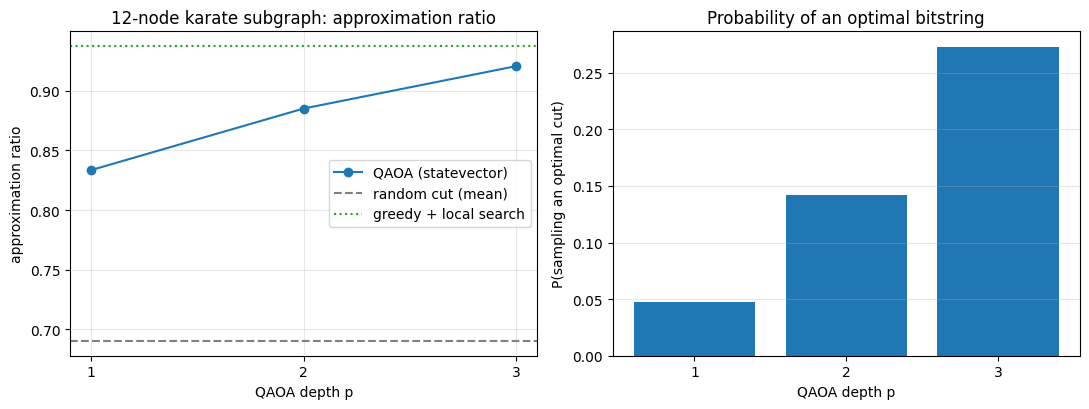

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
ps = [1, 2, 3]
ratios = [RESULTS12[p]["ratio"] for p in ps]
pops = [RESULTS12[p]["p_opt"] for p in ps]
axes[0].plot(ps, ratios, "o-", label="QAOA (statevector)")
axes[0].axhline(rand_cuts.mean() / C_MAX12, color="grey", ls="--", label="random cut (mean)")
axes[0].axhline(cut_of(greedy12_ls, edges12) / C_MAX12, color="tab:green", ls=":", label="greedy + local search")
axes[0].set_xticks(ps); axes[0].set_xlabel("QAOA depth p"); axes[0].set_ylabel("approximation ratio")
axes[0].set_title("12-node karate subgraph: approximation ratio"); axes[0].legend(); axes[0].grid(alpha=0.3)
axes[1].bar([str(p) for p in ps], pops, color="tab:blue")
axes[1].set_xlabel("QAOA depth p"); axes[1].set_ylabel("P(sampling an optimal cut)")
axes[1].set_title("Probability of an optimal bitstring"); axes[1].grid(alpha=0.3, axis="y")
plt.tight_layout(); plt.show()

In [7]:
# Full 34-node karate club: a statevector would need 2^34 amplitudes
n34 = G_full.number_of_nodes()
print(f"Statevector for {n34} qubits: 2^{n34} complex amplitudes = {2**n34 * 16 / 1e9:.0f} GB, not feasible here.")

edges34 = [tuple(e) for e in G_full.edges()]
rand34 = np.array([cut_of(rng.integers(0, 2, n34), edges34) for _ in range(20000)])
print(f"Random cuts (20000 samples): mean = {rand34.mean():.2f}, best = {rand34.max()}")

g34 = side_to_list(greedy_cut(G_full), n34)
print(f"Greedy cut: {cut_of(g34, edges34)}")

def local_search_multistart(G, restarts=500):
    best_side, best_val = None, -1
    nodes = list(G.nodes())
    for _ in range(restarts):
        side = {v: int(rng.integers(0, 2)) for v in nodes}
        side = local_search(G, side)
        val = sum(side[u] != side[v] for u, v in G.edges())
        if val > best_val:
            best_side, best_val = side, val
    return best_side, best_val

ls_side, ls_val = local_search_multistart(G_full, restarts=500)
print(f"Multi-start 1-flip local search (500 restarts): best cut = {ls_val}")

Statevector for 34 qubits: 2^34 complex amplitudes = 275 GB, not feasible here.


Random cuts (20000 samples): mean = 39.00, best = 54
Greedy cut: 52


Multi-start 1-flip local search (500 restarts): best cut = 61


In [8]:
# Goemans-Williamson style: SDP relaxation via Burer-Monteiro factorisation, then random-hyperplane rounding
def gw_relaxation(G, n, k=None, seed=SEED):
    k = n if k is None else k
    edge_idx = np.array([(u, v) for u, v in G.edges()])
    gen = np.random.default_rng(seed)
    X0 = gen.standard_normal((n, k))

    def f_and_grad(flat):
        X = flat.reshape(n, k)
        norms = np.linalg.norm(X, axis=1, keepdims=True)
        U = X / norms
        dots = np.sum(U[edge_idx[:, 0]] * U[edge_idx[:, 1]], axis=1)
        val = dots.sum()                                   # minimise sum of v_i . v_j  <=> maximise GW objective
        dU = np.zeros_like(U)
        np.add.at(dU, edge_idx[:, 0], U[edge_idx[:, 1]])
        np.add.at(dU, edge_idx[:, 1], U[edge_idx[:, 0]])
        dX = (dU - np.sum(dU * U, axis=1, keepdims=True) * U) / norms
        return val, dX.reshape(-1)

    res = minimize(f_and_grad, X0.reshape(-1), jac=True, method="L-BFGS-B")
    X = res.x.reshape(n, k)
    U = X / np.linalg.norm(X, axis=1, keepdims=True)
    return U, res.fun

def gw_rounding(U, G, trials=2000, seed=SEED):
    gen = np.random.default_rng(seed)
    edges = np.array(list(G.edges()))
    best, best_side = -1, None
    for _ in range(trials):
        r = gen.standard_normal(U.shape[1])
        side = (U @ r >= 0).astype(int)
        val = int(np.sum(side[edges[:, 0]] != side[edges[:, 1]]))
        if val > best:
            best, best_side = val, side
    return best, best_side

U34, sdp_val = gw_relaxation(G_full, n34)
relax_value = (G_full.number_of_edges() - sdp_val) / 2
gw_best, _ = gw_rounding(U34, G_full, trials=2000)
print(f"Relaxation value reached by the Burer-Monteiro factorisation = {relax_value:.3f} "
      "(a feasible point of the relaxation, not a certified upper bound on max cut)")
print(f"GW-style rounding (2000 hyperplanes): best cut = {gw_best}")
print(f"Best classical cut found on the 34-node graph: {max(gw_best, ls_val, cut_of(g34, edges34))}")

Relaxation value reached by the Burer-Monteiro factorisation = 63.489 (a feasible point of the relaxation, not a certified upper bound on max cut)
GW-style rounding (2000 hyperplanes): best cut = 61
Best classical cut found on the 34-node graph: 61


In [9]:
# Summary table
best34 = max(gw_best, ls_val, cut_of(g34, edges34))
rows = [
    ("Exact optimum (12 nodes, brute force)", C_MAX12, 1.0),
    ("QAOA p=1 (12 nodes, expectation)", RESULTS12[1]["expectation"], RESULTS12[1]["ratio"]),
    ("QAOA p=2 (12 nodes, expectation)", RESULTS12[2]["expectation"], RESULTS12[2]["ratio"]),
    ("QAOA p=3 (12 nodes, expectation)", RESULTS12[3]["expectation"], RESULTS12[3]["ratio"]),
    ("Greedy + local search (12 nodes)", cut_of(greedy12_ls, edges12), cut_of(greedy12_ls, edges12) / C_MAX12),
    ("Random cut mean (12 nodes)", rand_cuts.mean(), rand_cuts.mean() / C_MAX12),
    ("Best classical cut found (34 nodes)", best34, np.nan),
    ("Random cut mean (34 nodes)", rand34.mean(), np.nan),
]
print(f"{'method':42s} {'cut':>10s} {'ratio':>8s}")
for name, c, r in rows:
    print(f"{name:42s} {c:10.3f} {r:8.4f}")

method                                            cut    ratio
Exact optimum (12 nodes, brute force)          16.000   1.0000
QAOA p=1 (12 nodes, expectation)               13.337   0.8336
QAOA p=2 (12 nodes, expectation)               14.163   0.8852
QAOA p=3 (12 nodes, expectation)               14.731   0.9207
Greedy + local search (12 nodes)               15.000   0.9375
Random cut mean (12 nodes)                     11.045   0.6903
Best classical cut found (34 nodes)            61.000      nan
Random cut mean (34 nodes)                     39.004      nan


## Results
Measured in the executed notebook.

* **12-node karate subgraph, exact optimum (brute force over 4096 cuts):** max cut = 16, reached by 16 bitstrings (8 distinct partitions, since global flips give the same cut).
* **QAOA, statevector, COBYLA with random restarts:**
  * p = 1: expectation 13.337, approximation ratio 0.8336, probability of sampling an optimal cut 0.0475.
  * p = 2: expectation 14.163, approximation ratio 0.8852, probability of an optimal cut 0.1419.
  * p = 3: expectation 14.731, approximation ratio 0.9207, probability of an optimal cut 0.2729.
  * The best of 2048 shots reached the optimum (cut 16) at every depth. The approximation ratio rises with p, and so does the probability of an optimal sample.
* **Classical baselines on the same 12 nodes:** random cuts average 11.045 (ratio 0.6903) and the best of 10000 random cuts is 16. Greedy assignment, with and without 1-flip local search, gives 15 (ratio 0.9375).
* **Caveat:** at p = 1 to 3, the QAOA expectation value is below the greedy cut of 15 (expectation 14.731 at p = 3). QAOA is not better than the greedy heuristic at these depths on this graph; its advantage here is only that its best-shot value reaches the optimum.
* **Full 34-node karate club:** a statevector needs 2^34 amplitudes (275 GB), so QAOA was not run. Classical results: greedy cut 52; random cuts average 39.00 (best of 20000 samples: 54); multi-start 1-flip local search (500 restarts) finds 61; the Goemans-Williamson-style rounding (Burer-Monteiro relaxation, 2000 hyperplanes) also finds 61.
* **Caveat on the 34-node result:** 61 is the best cut found by heuristics. It is not proven optimal. The relaxation value printed by the notebook (63.489) is a feasible point of the semidefinite relaxation, not a certified upper bound, so it does not bound the optimum.
* **Simulator check:** the NumPy QAOA expectation at p = 1 agrees with a Qiskit circuit (`RZZ` and `RX` gates, `Statevector`) to 3.9e-14.

## Conclusions
1. **QAOA improves with depth but does not beat a cheap classical heuristic at these sizes.** On a 12-node, 22-edge subgraph of the karate club graph (exact maximum cut 16), QAOA reaches approximation ratios of 0.834, 0.885 and 0.921 at depths p = 1, 2 and 3, while a greedy algorithm with local search gets 15 (ratio 0.9375) and random cuts average 11.05 (0.690). QAOA's expected cut is better than random at every depth, but below the classical heuristic for p <= 3.
2. **Depth buys probability of the optimum, at rapidly growing cost.** The probability of measuring an optimal cut rises from 0.048 (p = 1) to 0.142 (p = 2) and 0.273 (p = 3), but the classical optimisation of the angles needed 2,830, 10,063 and 11,926 evaluations (27 s, 136 s and 210 s of simulation).
3. **The simulation was verified.** A hand-written NumPy expectation value matches Qiskit's to 4e-14 at the same angles.
4. **Scale is the real constraint.** The full 34-node graph needs 2^34 amplitudes (275 GB) to simulate, so QAOA cannot be run on it here; classical methods (multi-start local search and Goemans-Williamson-style rounding) both find a cut of 61, which is the best known to this notebook but not proven optimal. The 63.5 value from the semidefinite-style relaxation is a feasible point, not a certified bound.
5. **Limits.** One graph family, noiseless simulation, expectation values instead of sampled results for the ratios, and a local optimiser started from limited initial points; hardware noise would lower all QAOA numbers.

**Takeaway for the interview:** be precise about the claim. QAOA is a valid variational algorithm whose quality grows with depth, but at the sizes that can be simulated it is not competitive with simple classical heuristics; any advantage would have to appear at sizes that cannot be simulated.